In [14]:
import numpy as np
import pandas as pd

np.random.seed(42)

df = pd.read_csv('data/health_study_dataset.csv')

df.head()

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


In [15]:
cols = ['age', 'weight', 'height', 'systolic_bp', 'cholesterol']

stats_df = pd.DataFrame(
    {
        'Mean': df[cols].mean(),
        'Median': df[cols].median(),
        'Min': df[cols].min(),
        'Max': df[cols].max(),
    }
)

display(stats_df)

,Mean,Median,Min,Max
age,49.426250,50.00,18.0,90.00
weight,73.413000,73.20,33.7,114.40
height,171.849250,171.35,144.4,200.40
systolic_bp,149.178625,149.40,106.8,185.90
cholesterol,4.929150,4.97,2.5,7.88


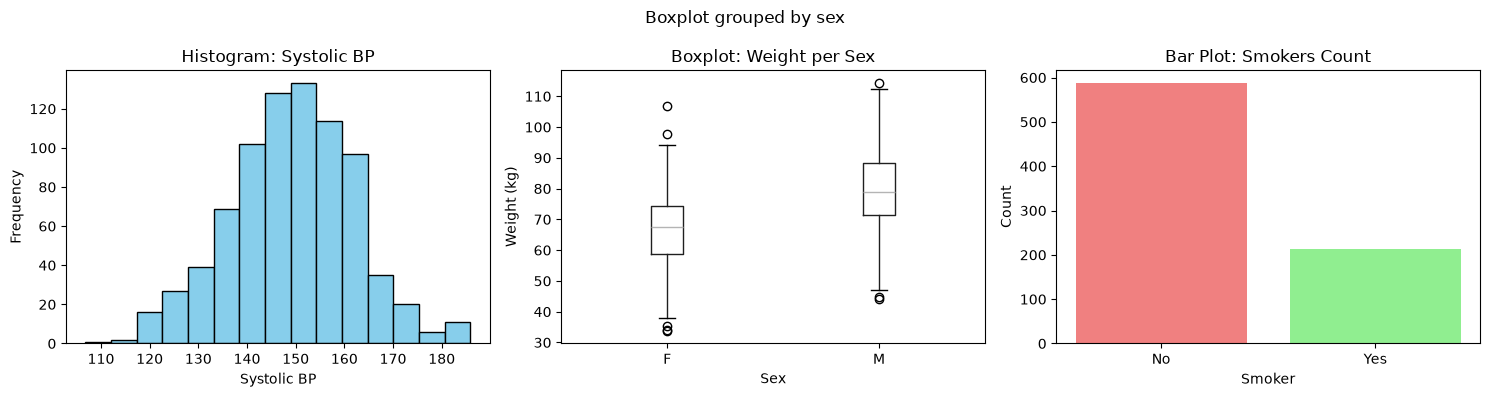

In [16]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(df['systolic_bp'].dropna(), bins=15, color='skyblue', edgecolor='black')
axes[0].set_title('Histogram: Systolic BP')
axes[0].set_xlabel('Systolic BP')
axes[0].set_ylabel('Frequency')

df.boxplot(column='weight', by='sex', ax=axes[1], grid=False)
axes[1].set_title('Boxplot: Weight per Sex')
axes[1].set_xlabel('Sex')
axes[1].set_ylabel('Weight (kg)')

smoker_counts = df['smoker'].value_counts()
axes[2].bar(smoker_counts.index, smoker_counts.values, color=['lightcoral', 'lightgreen'])
axes[2].set_title('Bar Plot: Smokers Count')
axes[2].set_xlabel('Smoker')
axes[2].set_ylabel('Count')

plt.tight_layout()
plt.show()

In [17]:
real_disease_rate = df["disease"].mean()

print(f"{real_disease_rate:.4f}")
print(f"{real_disease_rate * 100:.2f}")

0.0587
5.88


In [18]:
num_simulated_people = 1000

simulated_disease = np.random.choice(
    [0, 1],
    size=num_simulated_people,
    p=[1 - real_disease_rate, real_disease_rate],
)

simulated_rate = simulated_disease.mean()

print(f"{num_simulated_people}")
print(f"{simulated_rate:.4f}")
print(f"{simulated_rate * 100:.2f}%")

1000
0.0560
5.60%


In [19]:
import numpy as np

bp_data = df['systolic_bp'].dropna()
mean_bp = bp_data.mean()
std_bp = bp_data.std()
n = len(bp_data)

error_margin = 1.96 * (std_bp / np.sqrt(n))
ci_lower = mean_bp - error_margin
ci_upper = mean_bp + error_margin

print(f"Mean: {mean_bp:.2f}")
print(f"95% Confidence Interval: ({ci_lower:.2f}, {ci_upper:.2f})")

Mean: 149.18
95% Confidence Interval: (148.29, 150.07)


In [21]:
import numpy as np

smokers_bp = df[df['smoker'] == 'Yes']['systolic_bp'].dropna()
nonsmokers_bp = df[df['smoker'] == 'No']['systolic_bp'].dropna()

mean_diff = smokers_bp.mean() - nonsmokers_bp.mean()
pooled_std = np.sqrt(
    (
        (len(smokers_bp) - 1) * smokers_bp.var()
        + (len(nonsmokers_bp) - 1) * nonsmokers_bp.var()
    )
    / (len(smokers_bp) + len(nonsmokers_bp) - 2)
)
t_stat = mean_diff / (
    pooled_std * np.sqrt(1 / len(smokers_bp) + 1 / len(nonsmokers_bp))
)

print(f'Smokers Mean BP: {smokers_bp.mean():.2f}')
print(f'Non-Smokers Mean BP: {nonsmokers_bp.mean():.2f}')
print(f'Calculated t-statistic: {t_stat:.4f}')

Smokers Mean BP: 149.52
Non-Smokers Mean BP: 149.05
Calculated t-statistic: 0.4609


### Slutsats av hypotesprövningen
- **Rökare (medelvärde):** 149.52 mmHg
- **Icke-rökare (medelvärde):** 149.05 mmHg
- **Resultat:** T-värdet är 0.46, vilket visar att det inte finns någon statistiskt signifikant skillnad i systoliskt blodtryck mellan rökare och icke-rökare i detta dataset.